# EE-411 — Fundamentals of Inference and Learning
## Exercise Session 5 — Regularized least squares and gradient descent methods

In this fifth set of exercises, we will discuss how to solve least-squares problems with various techniques, and in particular the workhorse of modern machine learning: gradient descent. We shall first see how regularized least-squares methods such as Ridge and LASSO perform on a simple statistical problem. Then, we will introduce different gradient descent methods and use them on simple surfaces, studying their behavior. The same optimization methods apply to both a surface and a machine-learning loss function. In machine learning, however, minimizing training loss is only part of the task: we also want the fitted model to generalize to new data. We can build intuition about optimization by applying these methods to simple surfaces (see related blog posts [here](https://www.ruder.io/optimizing-gradient-descent/)).

**Learning objectives**
- Solve ridge regression using explicit formulas and gradient descent.
- Explore initialization, regularization and the learning rate.
- Implement iterative soft thresholding for LASSO.
- Visualize gradient descent, classical momentum and Nesterov accelerated gradient (NAG).

**Prerequisites**
- Linear algebra, derivatives, least squares and the brief introduction to soft thresholding from the lecture.
- Python packages: NumPy, SciPy and Matplotlib. All datasets are generated in the notebook.

Run the provided worked examples in order. **Only Exercise 3b is evaluated:** complete its two code sections marked `TODO`, then run the supplied comparison cell. No written explanation is required. The final bonus experiments are optional.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (9, 9)
plt.rcParams["font.size"] = 16
np.random.seed(40)

Classification isn't the only task within the scope of supervised machine learning. **Regression** is another equally important task with many complementary features. In regression, we are asked to make a real-valued prediction based upon a dataset of samples. As in classification, we can think of our dataset as an $N\times P$ matrix, with $N$ samples and $P$ features, but now instead of binary *labels* corresponding to a partition of the dataset, we are interested in matching real-valued *response* variables. 

In the case of simple linear regression, the problems we look at are of the form
$$\mathbf{y} = \mathbf{X}\mathbf{w} + \mathbf{\xi},$$
where $\mathbf{y}$ are our response variables, the matrix $\mathbf{X}$ is our dataset and the vector $\mathbf{\xi}$ represents some noise or uncertainty on our model. Our hope is to find the *explanatory* variables $\mathbf{w}$ which are able to match our observations and which generalize to future observations.

Here, we will consider solving regressions via **maximum a posteriori (MAP)** approaches. From the Bayesian perspective, we are often attempting to solve the problem
$${\rm arg~min}_{\mathbf{w}} \; \big(-\log P(\mathbf{y}|X, \mathbf{w}) - \log P(\mathbf{w})\big).
$$ 

Now, if we return to our definition of linear regression, we assume that the additive noise is *iid* Gaussian and also a uniform prior on the value of $\mathbf{w}$, we arrive (as seen during the lecture) at the ordinary least squares (OLS) problem, namely

$$
{\rm arg~min}_{\mathbf{w}} \quad ||\mathbf{y} - X\mathbf{w} ||_2^2,
$$

which we can interpret as a **maximum likelihood (ML)** solution.

Regressions, and specifically linear regressions, often form the basis of the ___"Do The Simplest Thing That Could Possibly Work."___ Many times in production, simple regressions provide good-enough performance which maximizes the trade-off against engineering costs (coding time, computer time). And, as we will later see, regressions can even be applied to solve classification tasks, either directly or using instead *logistic* regression. So, truly, regressions should be one of the first step when encountering a new data-science or ML problem. Things can only, hopefully, go up from here!


## Part A — Optimization

### Ridge regression
First, we need to discuss the many ways to solve the minimization problem. We are going to assume that we are interested in the ridge problem:
$$
\hat{\mathbf{w}} = {\rm arg~min}_{\mathbf{w}} \left( \frac 1n ||\mathbf{y} - X \mathbf{w} ||_2^2 + \lambda \|  \mathbf{w}\|_2^2 \right)$$ 
with $\mathbf{y} \in \mathbb R^n$,$\mathbf{w} \in \mathbb R^p$, and $X$ a $n \times p$ matrix. We have shown in the lecture that the solution should satisfy the normal equations:
$$
(X^T X + n \lambda {\mathbb 1}_p) \hat {\mathbf w} = X^T {\mathbf y}
$$
For any positive $\lambda$ the solution is unique (*question: why?*) and can be written either as (*question: why are these matrices invertible?*) 
$$
\hat {\mathbf w} = (X^T X + n\lambda {\mathbb 1}_p)^{-1} X^T {\mathbf y} = X^T (X X^T + n \lambda {\mathbb 1}_n)^{-1}  {\mathbf y}
$$

We shall see how to use these formulae. First we import the function `inv`, that allows us to invert matrices (indeed, if they are invertible)

In [2]:
from scipy.linalg import inv
import timeit

Then we generate an artificial set of data for the problem, using `randn` to create an $n\times p$ matrix $X$ and a $n$-dimensional vector $y$, in both of which every element is generated randomly according to a Normal distribution of unitary variance.

In [3]:
p = 50 #number of features
n = 250 #number of data points

X = np.random.randn(n,p)
y = np.random.randn(n,1)
lamb = 0.01

The following worked example computes the solution using both formulas:

In [4]:
Nrep = 100

w1 = inv(X.T@X+n*lamb*np.eye(p,p))@X.T@y
t1 = timeit.timeit('inv(X.T@X+n*lamb*np.eye(p,p))@X.T@y',"from __main__ import n,p,X,y,lamb,inv,np", number=Nrep)/Nrep
print("formula 1 took :",1000*t1,"ms \n and the result is w1=",w1[:3],"...")

w2 = X.T@inv(X@X.T+n*lamb*np.eye(n,n))@y
t2 = timeit.timeit('X.T@inv(X@X.T+n*lamb*np.eye(n,n))@y',"from __main__ import n,p,X,y,lamb,inv,np", number=Nrep)/Nrep
print("formula 2 took :",1000*t2,"ms \n and the result is w2=",w2[:3],"...")

formula 1 took : 0.27876199999980145 ms 
 and the result is w1= [[ 0.0680873]
 [ 0.0020364]
 [-0.1135461]] ...
formula 2 took : 10.543819000000099 ms 
 and the result is w2= [[ 0.0680873]
 [ 0.0020364]
 [-0.1135461]] ...


We repeat the experiment for different values of $n$ and $p$ to see when each formula is faster. The timing grid below is provided and may take a while to run.

The plot shows `time1 - time2` in milliseconds for each pair $(n,p)$: negative values mean formula 1 is faster, positive values mean formula 2 is faster, and the zero contour marks equal timings.

In [5]:
# It takes a lot to run!
Nt=15
table_p = np.linspace(50,250,num=Nt).astype(int)
table_n = np.linspace(50,250,num=Nt).astype(int)
time1 = np.zeros((Nt,Nt))
time2 = np.zeros((Nt,Nt))
lamb = 0.01
Nrep = 100

for i,n in enumerate(table_n):
  for j,p in enumerate(table_p):
    X = np.random.randn(n,p)
    y = np.random.randn(n,1)

    time1[i][j] = timeit.timeit('inv(X.T@X+n*lamb*np.eye(p,p))@X.T@y',"from __main__ import n,p,X,y,lamb,inv,np", number=Nrep)/Nrep
    time2[i][j] = timeit.timeit('X.T@inv(X@X.T+n*lamb*np.eye(n,n))@y',"from __main__ import n,p,X,y,lamb,inv,np", number=Nrep)/Nrep

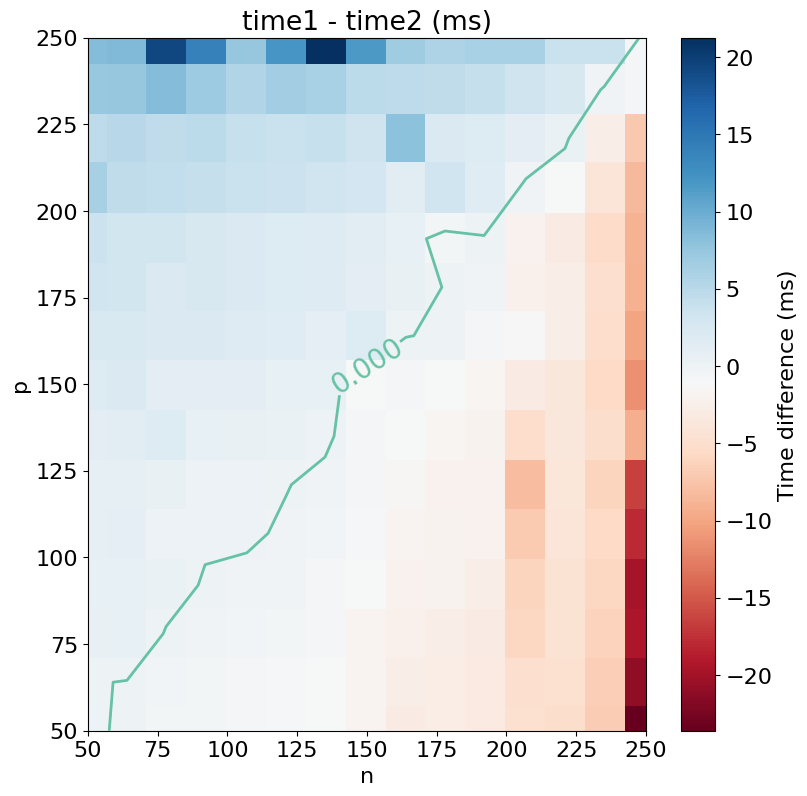

In [6]:
# Rows of time1/time2 correspond to n, columns to p.
Z = 1000 * (time1-time2).T  # milliseconds; transpose to put n on the horizontal axis

im = plt.pcolormesh(table_n, table_p, Z, cmap=plt.cm.RdBu, shading='nearest')
cset = plt.contour(table_n, table_p, Z, [0.], linewidths=2,
                   cmap=plt.cm.Set2)
plt.clabel(cset, inline=True, fmt='%1.3f', fontsize=20)
plt.colorbar(im, label="Time difference (ms)")
plt.xlabel('n')
plt.ylabel('p')
plt.xlim(table_n[0], table_n[-1])
plt.title('time1 - time2 (ms)')
plt.ylim(table_p[0], table_p[-1])

plt.show()

### Gradient Descent

An alternative to solve the problem is to use gradient descent! In order to keep number from exploding, we first define the cost function divided by the number of data as
$$
{\cal L}({\mathbf{w}}) = \frac {1}{2}  \bigg( \frac 1n ||\mathbf{y} - X \mathbf{w} ||_2^2 +  \lambda \|  \mathbf{w}\|_2^2 \bigg)$$


Therefore, the gradient reads
$$
\nabla_\mathbf{w} {\cal L}(\mathbf{w}) = -\frac 1n (X^T y - X^TX \mathbf {w}) + \lambda \mathbf {w} = \frac 1n (X^T (X {\mathbf w} - y)) + \lambda \mathbf {w}
$$



We import the function `norm`, which allows us to compute different matrix norms, and we choose some random initial weights

In [7]:
from numpy.linalg import norm
w0 = np.random.rand(p,1) #Pick some random weights to start the algorithm

#### Worked example 1 — Gradient descent

Calling $\eta$ the step size and $t_{max}$ the number of iterations, the provided function `gradient_descent` takes $X$, $y$, the initial weights $\mathbf{w}_0$, the iteration count, $\lambda$ and $\eta$. It returns the final weights and the cost $\mathcal L(\mathbf w)$ recorded before each update. Run it with the experiments below.

In [8]:
def gradient_descent(X, y, w0, iterations, l2, eta):
    n = X.shape[0]
    w = w0.copy()
    past_costs = []
    for _ in range(iterations):
        prediction =  X@w
        error = prediction - y
        cost = (1/(2*n) * np.dot(error.T, error) + 1/2.0 * l2 * np.dot(w.T,w))[0,0]
        past_costs.append(cost)
        w = w - (eta * (np.dot(X.T, error)/n+l2*w))
    return w, past_costs

For $n=30$, $p=3$, $t_{max}=50$ and $\lambda=0.001$, the following code tries $\eta\in[0.03,0.1,0.3,1,2,3]$. Run it to see the cost across iterations and the distance between the final weights and the exact ridge solution.

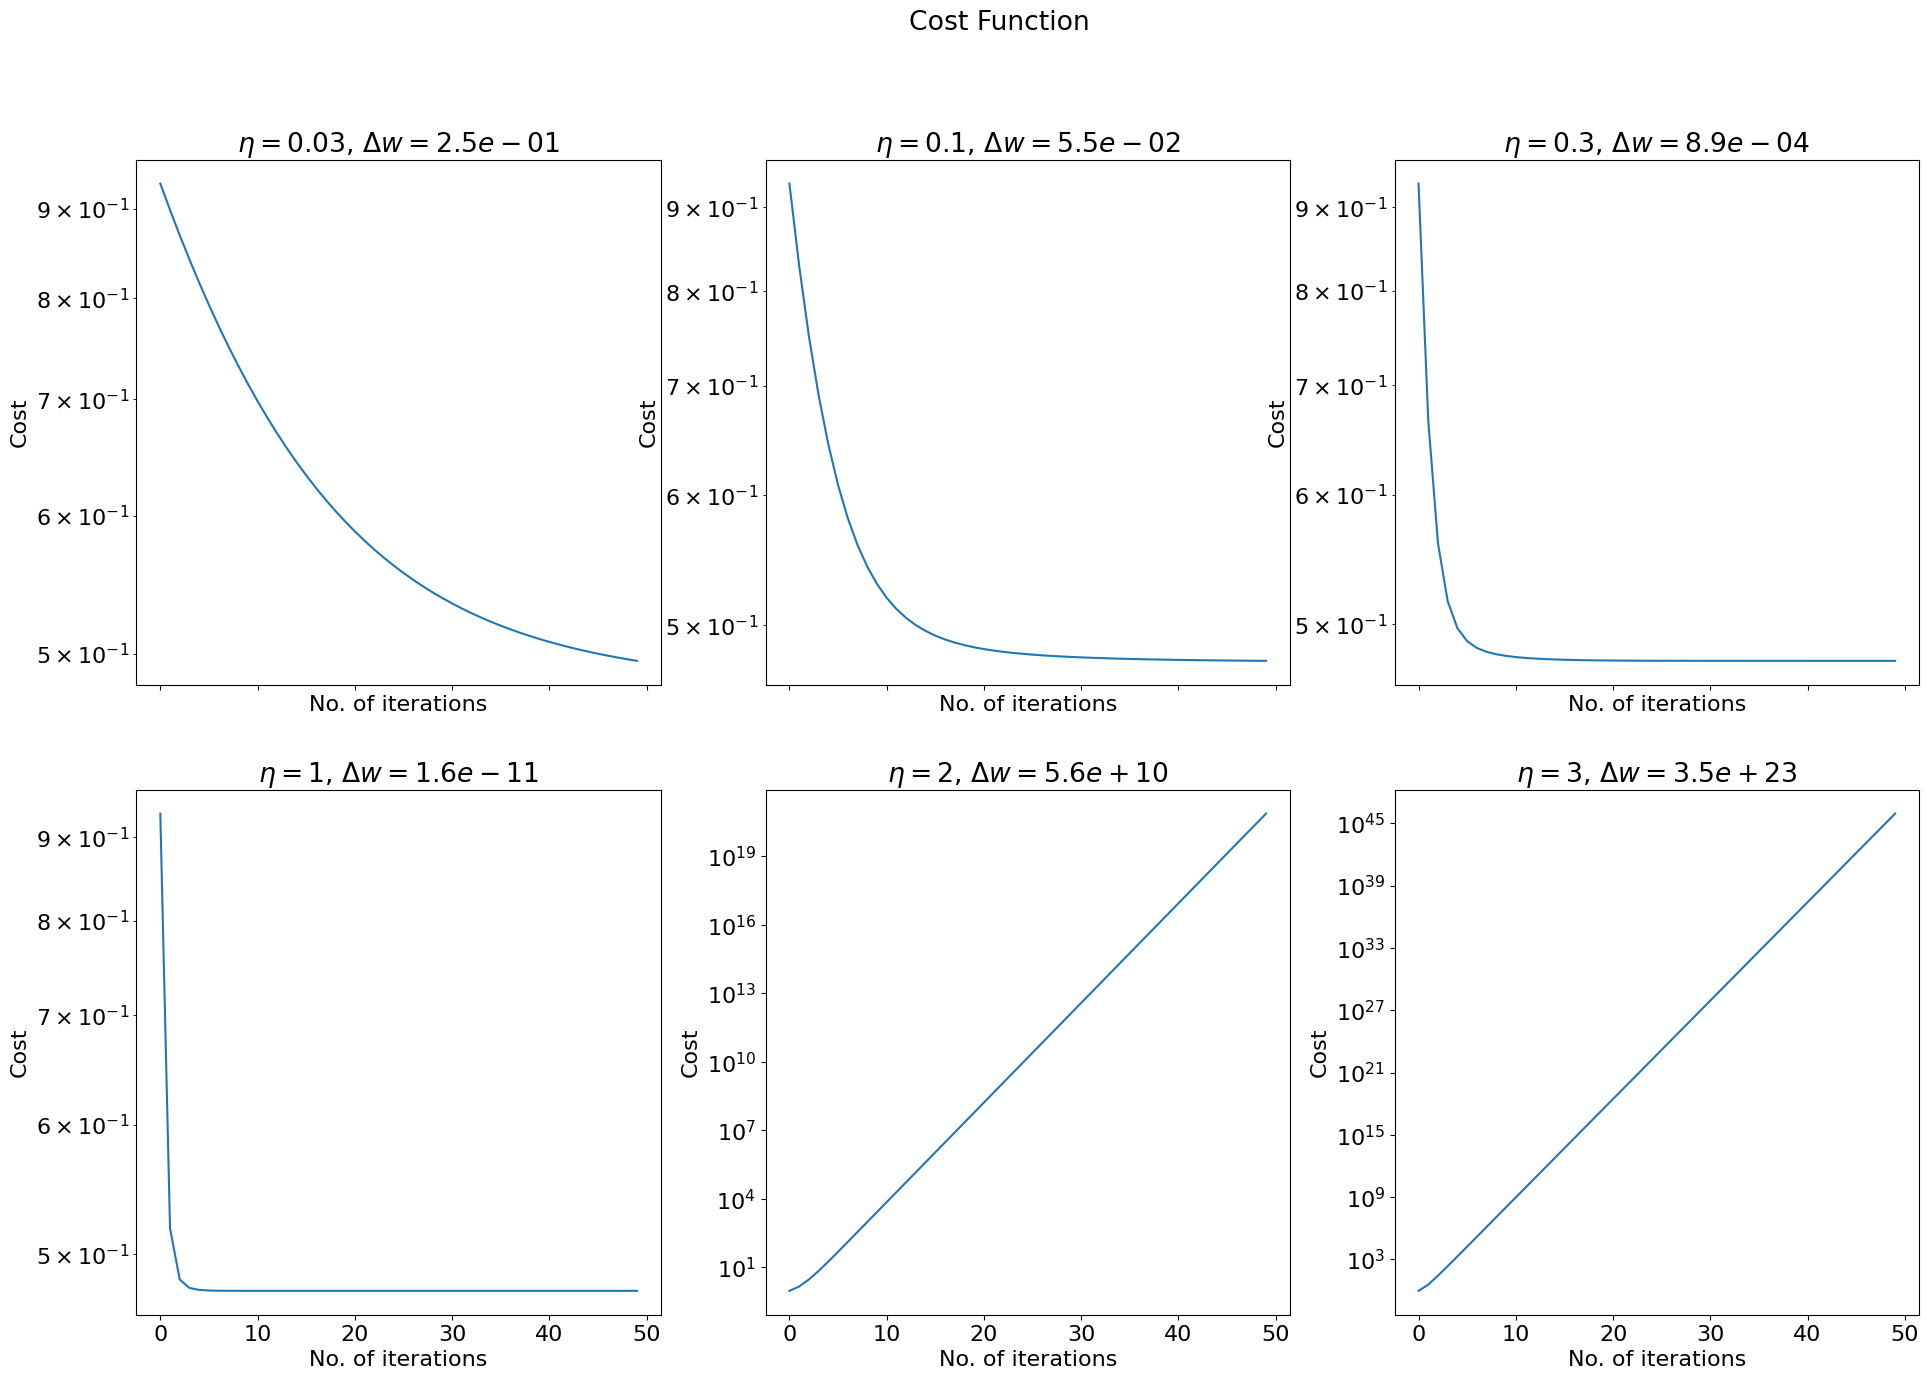

In [9]:
n=30
p=3

X = np.random.randn(n,p)
y = np.random.randn(n,1)
w0 = np.random.rand(p,1)
lamb = 0.001

iterations = 50 #No. of iterations
eta = [0.03,0.1,0.3,1,2,3]

w_ref = inv(X.T@X+n*lamb*np.eye(p,p))@X.T@y

fig, axs = plt.subplots(2,3, figsize=(23,15), sharex=True)
plt.suptitle('Cost Function')
for i,e in enumerate(eta):
  w, past_costs = gradient_descent(X, y, w0, iterations, lamb, e)
  axs[int(i/3)][i%3].plot(past_costs)
  axs[int(i/3)][i%3].set_title(fr'$\eta = {e}$, $\Delta w = {norm(w_ref-w):1.1e}$')
  axs[int(i/3)][i%3].set_xlabel('No. of iterations')
  axs[int(i/3)][i%3].set_ylabel('Cost')
  axs[int(i/3)][i%3].set_yscale("log")

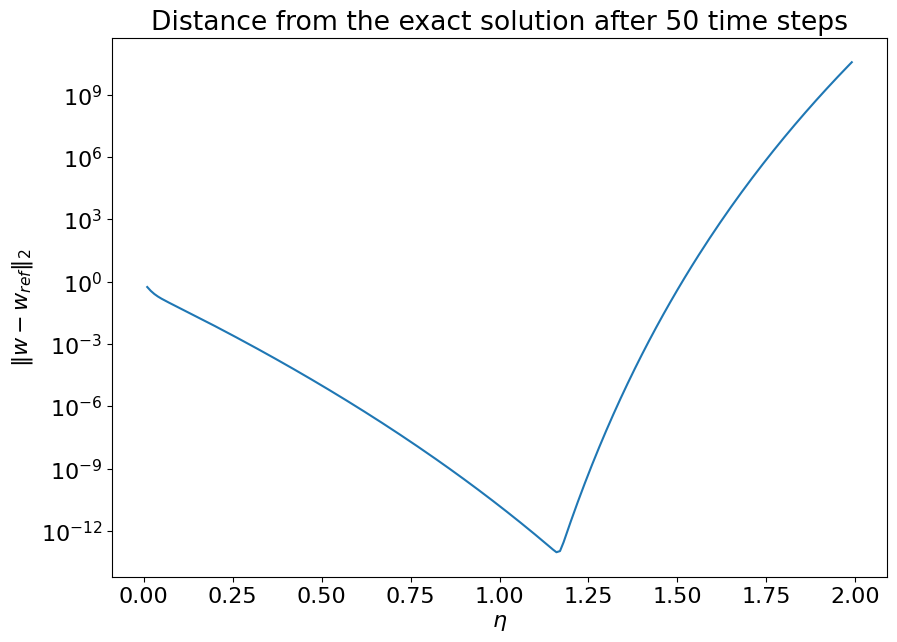

In [10]:
eta = np.arange(0.01,2,0.01)
table_w = np.zeros(len(eta))

for j,e in enumerate(eta):
  w, past_costs = gradient_descent(X, y, w0, iterations, lamb, e)
  table_w[j] = norm(w_ref-w)

fig = plt.figure(figsize=(10,7))
plt.title('Distance from the exact solution after 50 time steps')
plt.xlabel(r'$\eta$')
plt.ylabel(r'$\|w-w_{ref}\|_2$')
plt.plot(eta,table_w)
plt.yscale("log")
plt.show()

### Ordinary least squares and implicit regularization

First, revisit the current dataset with $n=30>p=3$ and compare ordinary least squares with the ridge solution above. Then, in Worked example 2, we switch to $n<p$ and compare solutions found by gradient descent with $\lambda=0$.

The ordinary least-squares problem is
$$
\hat{\mathbf w}=\operatorname*{arg\,min}_{\mathbf w}\|\mathbf y-X\mathbf w\|_2^2.
$$

We try to use the formula

$$
\hat {\mathbf w} = (X^T X )^{-1} X^T {\mathbf y}
$$

to get the solution.


In [11]:
inv(X.T@X)@(X.T@y) - w_ref

array([[-2.86245383e-04],
       [-6.06823773e-05],
       [ 5.43204230e-04]])

Here $X$ has full column rank. The ordinary least-squares solution is close to, but not identical to, the ridge solution computed with $\lambda=0.001$.

When $X$ has full row rank, the minimum-norm solution can instead be written as
$$
\hat {\mathbf w}_{ln} = X^T (X X^T)^{-1} {\mathbf y}.
$$

For the current $n>p$ dataset, $XX^T$ is singular. The following cell deliberately tries this invalid inverse to illustrate that it can fail or produce unreliable numerical results.

In [12]:
try:
    print(X.T @ inv(X @ X.T) @ y - w_ref)
except np.linalg.LinAlgError:
    print("XX^T is singular: its ordinary inverse does not exist.")

[[  0.82653264]
 [-24.75312847]
 [-13.53835188]]


This failure or large discrepancy comes from attempting an ordinary inverse of a singular matrix. It is not a pseudoinverse calculation. Check the rank below; the next example uses a full-row-rank dataset where the minimum-norm formula applies.

In [13]:
print("Rank of XX^T:", np.linalg.matrix_rank(X @ X.T))
print("Shape of XX^T:", (X @ X.T).shape)

Rank of XX^T: 3
Shape of XX^T: (30, 30)


#### Worked example 2 — Initialization and implicit regularization

The following code sets $p=100$, $n=20$ and $\lambda=0$, then runs gradient descent from random and zero initial weights. Run it to compare both results with the minimum-norm solution $\hat{\mathbf w}_{ln}$.

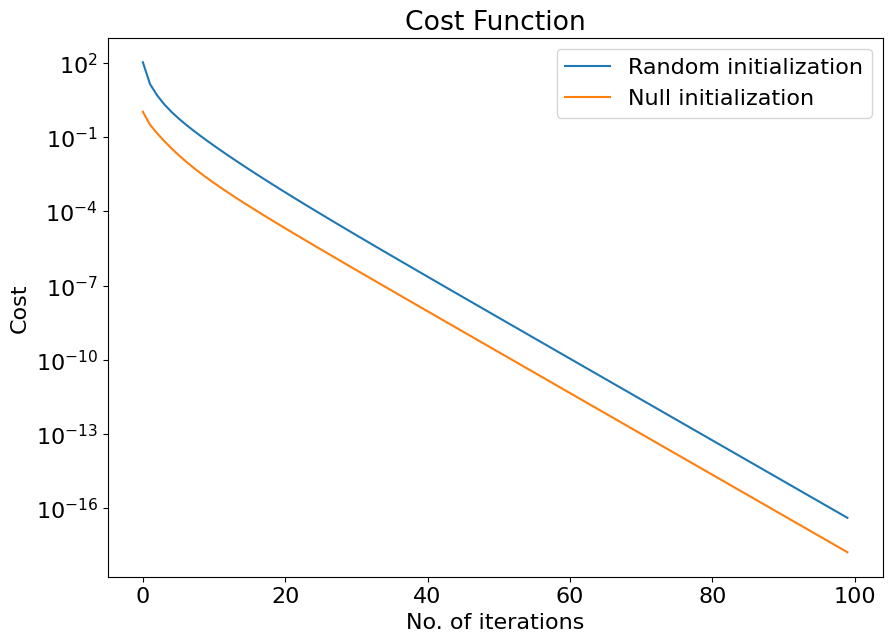

In [14]:
p = 100 #data dimension
n = 20 #number of datapoints

X = np.random.randn(n,p)
y = np.random.randn(n,1)
lamb = 0
eta = 0.1 #Step size
iterations = 100 #No. of iterations
w0_r = np.random.randn(p,1) #Pick some random values to start with
w0_z = np.zeros((p,1)) #Start with a zero vector

fig = plt.figure(figsize=(10,7))
w_r, past_costs_r = gradient_descent(X, y, w0_r, iterations, lamb, eta)
w_z, past_costs_z = gradient_descent(X, y, w0_z, iterations, lamb, eta)
plt.title('Cost Function')
plt.xlabel('No. of iterations')
plt.ylabel('Cost')
plt.plot(past_costs_r, label='Random initialization')
plt.plot(past_costs_z, label='Null initialization')
plt.yscale('log')
plt.legend()
plt.show()
w_ref = X.T@inv(X@X.T)@y

In [15]:
print(r'Difference of w_r from optimum w is {:.3f}'.format(norm(w_ref-w_r)))
print(r'Difference of w_z from optimum w is {}'.format(norm(w_ref-w_z)))

Difference of w_r from optimum w is 8.404
Difference of w_z from optimum w is 1.1538827822688637e-09


With $n<p$, this full-row-rank dataset admits many weight vectors that fit the observations exactly. Both runs can therefore approach zero training loss while ending with different weights. The reference `w_ref` is the exact-fitting solution with the smallest Euclidean norm $\|w\|_2$: the plot compares losses, while the printed distances compare weights with this reference.

Gradient descent leaves unchanged any initial weight component $v$ satisfying $Xv=0$, because this component does not affect predictions. Random initialization generally includes such a component; zero initialization does not. With a suitable step size and enough iterations, zero-initialized gradient descent converges to `w_ref`. This preference for the minimum-norm solution is called **implicit regularization**, even though $\lambda=0$.


### LASSO and sub-gradient descent

Another cost function that shall be useful is the one corresponding to LASSO:
$$
{\cal L}({\mathbf{w}}) =  \frac{1}{2n} ||\mathbf{y} - X \mathbf{w} ||_2^2 +  \lambda \|  \mathbf{w}\|_1 
$$

One choice of subgradient, taking `np.sign(0) = 0`, is
$$
\nabla_\mathbf{w} {\cal L}(\mathbf{w}) = -\frac 1n (X^T y - X^TX \mathbf {w}) + \lambda {\rm sign} ({\mathbf w}) = \frac 1n (X^T (X {\mathbf w}-y)) + \lambda {\rm sign}({\mathbf w})
$$

#### Worked example 3 — LASSO by subgradient descent

The provided `gradient_descent_lasso` uses `np.sign()` for the $L_1$ penalty. It returns the final weights and the cost recorded before each update. Run it on the new dataset with $p=100$ and $n=20$; it will serve as the baseline for Exercise 3b.

In [16]:
def gradient_descent_lasso(X, y, w, iterations, l1, eta):
    past_costs = []
    n= len(y)
    for i in range(iterations):
        prediction =  X@w
        error = prediction - y
        cost = (1/(2*n) * np.dot(error.T, error) + l1 * np.linalg.norm((w), ord=1))[0,0]
        past_costs.append(cost)
        w = w - eta * (np.dot(X.T, error)/n + l1*np.sign(w))
    return w, past_costs

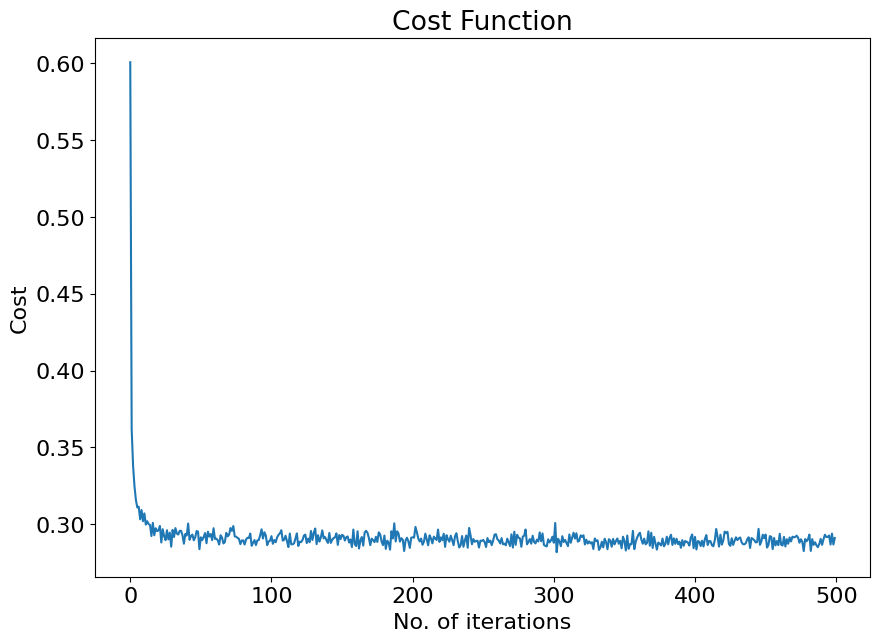

In [17]:
p = 100 #data dimension
n = 20 #number of datapoints

X = np.random.randn(n,p)
y = np.random.randn(n,1)
lamb = 0.1
eta = 0.9 / (np.linalg.norm(X, ord=2)**2 / n) # Stable step size for the squared-error term
iterations = 500 #No. of iterations
w0 = np.zeros((p,1)) #Start with a zero vector

fig = plt.figure(figsize=(10,7))
w, past_costs = gradient_descent_lasso(X, y, w0, iterations, lamb, eta)
plt.title('Cost Function')
plt.xlabel('No. of iterations')
plt.ylabel('Cost')
plt.plot(past_costs)
plt.show()

### Exercise 3b — LASSO with iterative soft thresholding [Evaluated]

The **iterative shrinkage-thresholding algorithm (ISTA)** solves the same LASSO problem introduced above:
$$
\mathcal L(\mathbf w)=\frac{1}{2n}\|X\mathbf w-\mathbf y\|_2^2+\lambda\|\mathbf w\|_1.
$$

As seen briefly in class, each iteration has two steps:

1. Take a gradient step using only the squared-error term:
   $$\mathbf z=\mathbf w-\frac{\eta}{n}X^T(X\mathbf w-\mathbf y).$$
2. Apply soft thresholding to each coefficient:
   $$w_j^{\mathrm{new}}=S_{\eta\lambda}(z_j),\qquad S_\tau(z)=\operatorname{sign}(z)\max(|z|-\tau,0).$$

Soft thresholding shrinks coefficients towards zero and sets those with magnitude at most $\tau$ exactly to zero. This handles the $L_1$ penalty directly, while the gradient step handles the smooth squared-error term.

Complete only the two code sections marked `TODO` below: the soft-thresholding operation and the ISTA update. Replace each `raise NotImplementedError(...)` placeholder with your code. The loop and cost calculation are provided. Then run the supplied comparison cell, which plots the common LASSO objective and reports the number of zero coefficients for both methods. No written explanation is required.

Use the dataset, zero initialization, $\lambda$ and iteration count from Worked example 3. The supplied step size is $\eta=0.9/L$, with $L=\|X\|_2^2/n$, so the gradient step is stable.

In [26]:
def my_soft_threshold(tau, beta):
    """Apply soft thresholding with threshold tau elementwise to beta."""
    # TODO 1: implement the soft-thresholding operation defined above.
    # YOUR CODE HERE
    return np.sign(beta) * np.maximum(np.abs(beta) - tau, 0) # beta corresponds to w in ISTA

In [27]:
def ISTA(X, y, w, iterations, l1, eta):
    n = X.shape[0]
    w = w.copy()
    past_costs = []
    for _ in range(iterations):
        error = X @ w - y
        cost = (np.dot(error.T, error)/(2*n) + l1*np.linalg.norm(w, ord=1))[0, 0]
        past_costs.append(cost)
        # TODO 2: take the squared-error gradient step, then apply soft thresholding.
        # YOUR CODE HERE
        # 1. Gradient step
        w -=eta / n * X.T @ error
        # 2. Soft thresholding
        w = my_soft_threshold(eta * l1, w)
    return w, past_costs

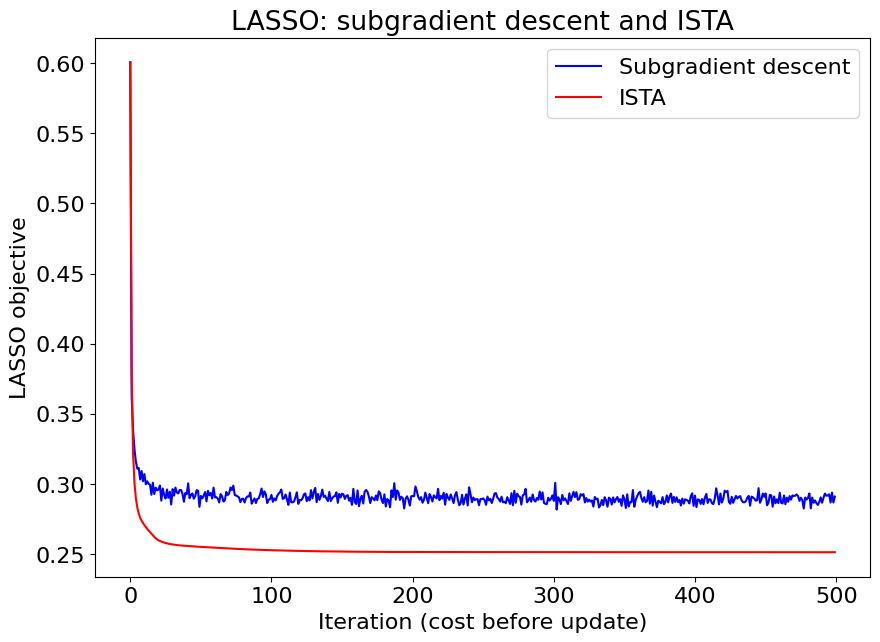

Zero coefficients (absolute value < 1e-08):
Subgradient descent: 0 / 100
ISTA: 83 / 100


In [28]:
# Provided comparison: both methods use the same data and parameters.
try:
    w2, past_costs2 = ISTA(X, y, w0, iterations, lamb, eta)
except NotImplementedError as error:
    print(error)
    print("Complete both TODOs above, then rerun this comparison cell.")
else:
    w, past_costs = gradient_descent_lasso(X, y, w0, iterations, lamb, eta)
    plt.figure(figsize=(10, 7))
    plt.title('LASSO: subgradient descent and ISTA')
    plt.xlabel('Iteration (cost before update)')
    plt.ylabel('LASSO objective')
    plt.plot(past_costs, '-b', label='Subgradient descent')
    plt.plot(past_costs2, '-r', label='ISTA')
    plt.legend()
    plt.show()

    zero_tolerance = 1e-8
    print(f"Zero coefficients (absolute value < {zero_tolerance:g}):")
    print(f"Subgradient descent: {np.count_nonzero(np.abs(w) < zero_tolerance)} / {w.size}")
    print(f"ISTA: {np.count_nonzero(np.abs(w2) < zero_tolerance)} / {w2.size}")

## Part B — Surfaces

We will consider two simple surfaces. The first is a quadratic minimum:

$$
z=ax^2+by^2-1\,,
$$

where $a,b>0$. The constant $-1$ shifts the surface vertically without changing its gradient.

The second is the [Matyas function](https://en.wikipedia.org/wiki/Test_functions_for_optimization), a convex function often used to test optimization algorithms:

$$
z(x,y) = 0.26(x^2 + y^2) - 0.48xy.
$$


These surfaces can be plotted using the code below: 

In [29]:
#Make 3D plots
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.colors import LogNorm

#Function for plotting

def plot_surface(x, y, z, azim=-60, elev=40, dist=10, cmap="RdYlBu_r"):

    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    plot_args = {'rstride': 1, 'cstride': 1, 'cmap':cmap, 'linewidth': 20, 'antialiased': True, 'vmin': -2, 'vmax': 2} #parameters for the plots
    ax.plot_surface(x, y, z, **plot_args)
    ax.view_init(azim=azim, elev=elev) #point of view
    ax.dist=dist
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_zlim(-2, 2)

    plt.xticks([-1, -0.5, 0, 0.5, 1], ["-1", "-1/2", "0", "1/2", "1"])
    plt.yticks([-1, -0.5, 0, 0.5, 1], ["-1", "-1/2", "0", "1/2", "1"])
    ax.set_zticks([-2, -1, 0, 1, 2])
    ax.set_zticklabels(["-2", "-1", "0", "1", "2"])

    ax.set_xlabel("x", fontsize=18)
    ax.set_ylabel("y", fontsize=18)
    ax.set_zlabel("z", fontsize=18)
    return fig, ax;

#Overlay the trajectory of GD on a contour plot

def overlay_trajectory_contour(ax,trajectory, label,color='k',lw=2):
    xs=trajectory[:,0]
    ys=trajectory[:,1]
    ax.plot(xs,ys, color, label=label,lw=lw)
    return ax;

We now define the functions for the Matyas function and the respective gradient, that we will need for the algorithms:

In [30]:
# Define matyas_surface and the respective gradient

def matyas_surface(x,y):
    return 0.26*(x**2 + y**2) - 0.48*x*y

def grad_matyas_surface(params):
    x=params[0]
    y=params[1]
    grad_x= 0.52*x-0.48*y
    grad_y= 0.52*y-0.48*x
    return [grad_x,grad_y]

#### Worked example 4 — A quadratic minimum

The quadratic surface and its gradient are provided below. Run their definitions before plotting the surfaces.

In [31]:
# Define minima_surface and the respective gradient

def minima_surface(x,y,a=1,b=1):
    return a*x**2+b*y**2-1

def grad_minima_surface(params,a=1,b=1):
    x=params[0]
    y=params[1]
    grad_x= 2*a*x
    grad_y= 2*b*y
    return [grad_x,grad_y]

Run the following code to plot both surfaces, using $a=1.5$ and $b=2$ for the quadratic minimum.

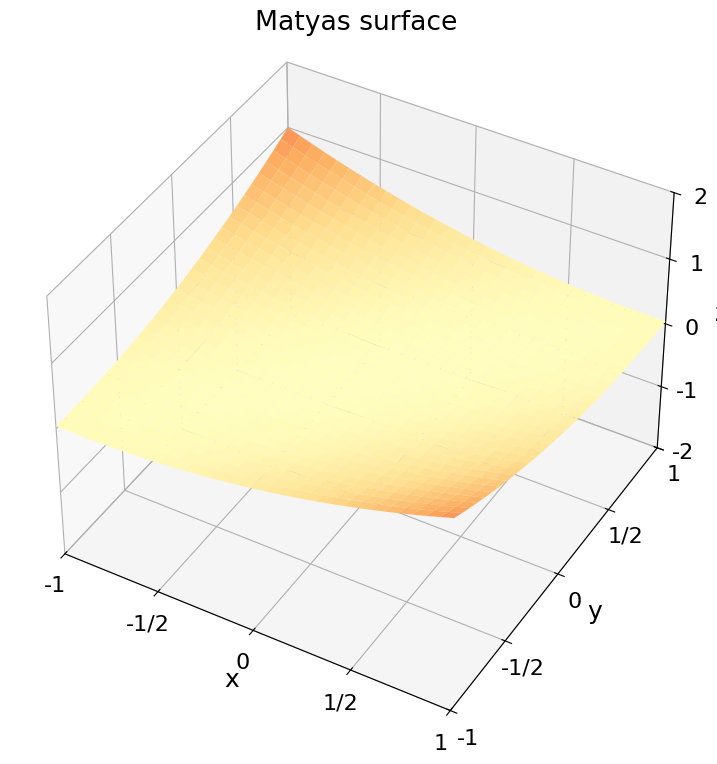

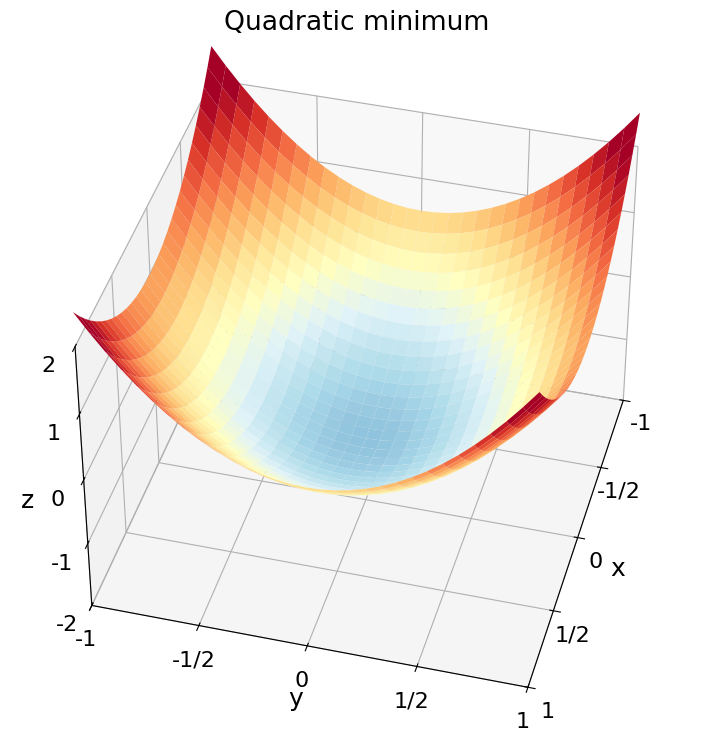

In [32]:
#Make plots of the surfaces

plt.close() # closes previous plots
x, y = np.mgrid[-1:1:31j, -1:1:31j] #31 points between -1 and 1
fig1,ax1=plot_surface(x,y,matyas_surface(x,y))
ax1.set_title("Matyas surface")
plt.show()

# Plot the quadratic minimum

fig2,ax2=plot_surface(x,y,minima_surface(x,y,1.5,2),15)
ax2.set_title("Quadratic minimum");

### Gradient descent with and without momentum

Now, let's visualize various gradient descent algorithms used in machine learning. We will be especially interested in trying to understand how various hyperparameters, especially the learning rate, affect our performance.

As always, we will work with some parameters $\mathbf{w}$ and we have an energy function we are trying to minimize, usually denoted by ${\cal L}(\mathbf{w})$.

<b>Gradient Descent</b>

We start by considering a simple gradient descent method. In this method,
we will take steps in the direction of the negative local gradient. Given some parameters $\mathbf{w}$, we adjust them at each iteration so that

$$\mathbf{w}_{t+1}= \mathbf{w}_t - \eta_t \nabla_\mathbf{w} {\cal L}(\mathbf{w}),$$

where we have introduced the learning rate $\eta_t$ that controls how large a step we take. In general, the algorithm is extremely sensitive to the choice of $\eta_t$. If $\eta_t$ is too large, then one can wildly oscillate around minima and miss important structure at small scales. This problem is amplified if our gradient computations are noisy and inexact (as is often the case in machine learning applications). If $\eta_t$ is too small, then the learning/minimization procedure becomes extremely slow. This raises the natural question: <i> What sets the natural scale for the learning rate and how can we adaptively choose it?</i>

<b>Gradient Descent with Momentum</b>

One problem with gradient descent is that it has no memory of where the "ball rolling down the hill" comes from. This can be an issue when there are many shallow minima in our landscape. If we make an analogy with a ball rolling down a hill, the lack of memory is equivalent to having no inertia or momentum (i.e. completely overdamped dynamics). Without momentum, the ball has no kinetic energy and cannot climb out of shallow minima. 

Momentum becomes especially important when we start thinking about **stochastic gradient descent** with noisy, stochastic estimates of the gradient. In this case, we should remember where we were coming from and not react drastically to each new update.



Inspired by this, we can add a memory or momentum term to the stochastic gradient descent term above:

$$
v_{t}=\gamma v_{t-1}+\eta_{t}\nabla_\mathbf{w} {\cal L}(\mathbf{w}_t),\\
\mathbf{w}_{t+1}= \mathbf{w}_t -v_{t},
$$

with $0\le \gamma < 1$ called the momentum parameter. When $\gamma=0$, this reduces to ordinary gradient descent, and increasing $\gamma$ increases the inertial contribution to the gradient. From the equations above, we can see that typical memory lifetimes of the gradient is given by $(1-\gamma)^{-1}$. For $\gamma=0$ as in gradient descent, the lifetime is just one step. For $\gamma=0.9$, we typically remember a gradient for ten steps. We will call this gradient descent **classical momentum** or CM for short.

**NAG** 

A final widely used variant of gradient descent with momentum is called the Nesterov accelerated gradient (NAG). In NAG, rather than calculating the gradient at the current position, one calculates the gradient at the position momentum will carry us to at time $t+1$, namely, $\mathbf{w}_t -\gamma v_{t-1}$. Thus, the update becomes
$$
v_{t}=\gamma v_{t-1}+\eta_{t}\nabla_\mathbf{w} {\cal L}(\mathbf{w}_t-\gamma v_{t-1})\\
\mathbf{w}_{t+1}= \mathbf{w}_t -v_{t}
$$

The following code provides standard gradient descent. Run it before the trajectory experiments below.

In [33]:
#Simple gradient descent

def gd(grad, init, n_epochs=1000, eta=10**-4, noise_strength=0):
    params=np.array(init)
    param_traj=np.zeros([n_epochs+1,2])
    param_traj[0,]=init
    v=0;
    for j in range(n_epochs):
        noise=noise_strength*np.random.randn(params.size)
        v=eta*(np.array(grad(params))+noise)
        params=params-v
        param_traj[j+1,]=params
    return param_traj

#### Worked example 5 — Classical momentum and NAG

Run the provided implementations of gradient descent with classical momentum (CM) and Nesterov accelerated gradient (NAG). Their updates follow the equations above.

In [34]:
#Gradient descent with momentum

def gd_with_mom(grad, init, n_epochs=5000, eta=10**-4, gamma=0.9,noise_strength=0):
    params=np.array(init)
    param_traj=np.zeros([n_epochs+1,2])
    param_traj[0,]=init
    v=0
    for j in range(n_epochs):
        noise=noise_strength*np.random.randn(params.size)
        v=gamma*v+eta*(np.array(grad(params))+noise)
        params=params-v
        param_traj[j+1,]=params
    return param_traj

#Nesterov accelerated gradient descent

def NAG(grad, init, n_epochs=5000, eta=10**-4, gamma=0.9,noise_strength=0):
    params=np.array(init)
    param_traj=np.zeros([n_epochs+1,2])
    param_traj[0,]=init
    v=0
    for j in range(n_epochs):
        noise=noise_strength*np.random.randn(params.size)
        params_nesterov=params-gamma*v
        v=gamma*v+eta*(np.array(grad(params_nesterov))+noise)
        params=params-v
        param_traj[j+1,]=params
    return param_traj

### Experiments with GD, CM and NAG

Run the plot below to explore gradient descent (GD) on the Matyas surface for $\eta=0.1,0.5,1,2$. Observe how the trajectories change with the learning rate. Different starting points are used to keep the trajectories visually separate.

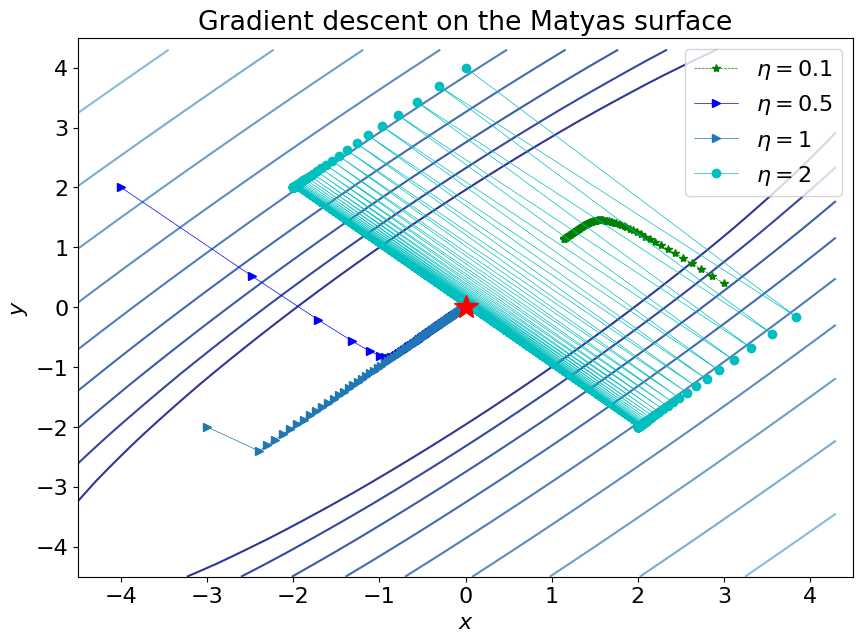

In [35]:
# Investigate effect of learning rate in GD
plt.close()
fig = plt.figure(figsize=(10,7))
ax1 = fig.add_subplot(111)
x, y = np.meshgrid(np.arange(-4.5, 4.5, 0.2), np.arange(-4.5, 4.5, 0.2))
z=np.abs(matyas_surface(x,y))

#initial point
init4=[0,4]
init2=[-4,2]
init3=[-3,-2]
init1=[3,0.4]
eta1=0.1
eta2=0.5
eta3=1
eta4=2

ax1.contour(x, y, z, levels=np.logspace(0.0, 5, 35), norm=LogNorm(), cmap="RdYlBu_r")
ax1.set_title('Gradient descent on the Matyas surface')
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')

ax1.set_xlim((-4.5, 4.5))
ax1.set_ylim((-4.5, 4.5))

gd_1=gd(grad_matyas_surface,init1, n_epochs=100, eta=eta1)
gd_2=gd(grad_matyas_surface,init2, n_epochs=100, eta=eta2)
gd_3=gd(grad_matyas_surface,init3, n_epochs=100, eta=eta3)
gd_4=gd(grad_matyas_surface,init4, n_epochs=100, eta=eta4)

overlay_trajectory_contour(ax1,gd_1,r'$\eta=$%s'% eta1,'g--*', lw=0.5)
overlay_trajectory_contour(ax1,gd_2,r'$\eta=$%s'% eta2,'b->', lw=0.5)
overlay_trajectory_contour(ax1,gd_3,r'$\eta=$%s'% eta3,'->', lw=0.5)
overlay_trajectory_contour(ax1,gd_4,r'$\eta=$%s'% eta4,'c-o', lw=0.5)

ax1.plot(0,0, 'r*', markersize=18)

plt.legend()
plt.show()

#### Bonus 6 — Anisotropy (optional)

Optionally adapt the preceding trajectory plot to the quadratic minimum. Try different positive values of $a$ and $b$ to explore the effect of unequal curvature along the two axes.

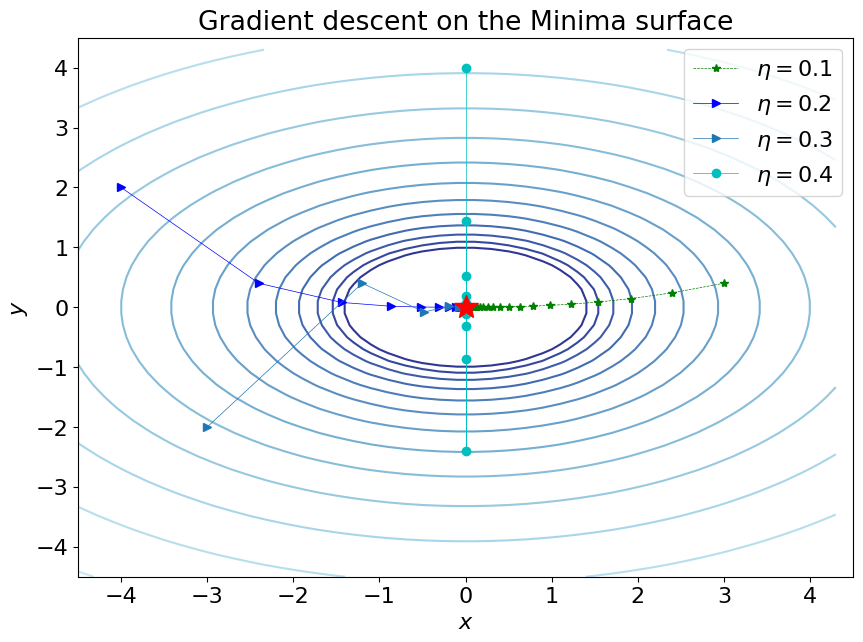

In [57]:
# Optional space for the quadratic-surface experiment.

# Investigate effect of learning rate in GD
plt.close()
fig = plt.figure(figsize=(10,7))
ax1 = fig.add_subplot(111)
x, y = np.meshgrid(np.arange(-4.5, 4.5, 0.2), np.arange(-4.5, 4.5, 0.2))
z=np.abs(minima_surface(x,y, 1, 2))

#initial point
init4=[0,4]
init2=[-4,2]
init3=[-3,-2]
init1=[3,0.4]
eta1=0.1
eta2=0.2
eta3=0.3
eta4=0.4

ax1.contour(x, y, z, levels=np.logspace(0.0, 5, 35), norm=LogNorm(), cmap="RdYlBu_r")
ax1.set_title('Gradient descent on the Minima surface')
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')

ax1.set_xlim((-4.5, 4.5))
ax1.set_ylim((-4.5, 4.5))

gd_1=gd(lambda p: grad_minima_surface(p, 1, 2),init1, n_epochs=100, eta=eta1)
gd_2=gd(lambda p: grad_minima_surface(p, 1, 2),init2, n_epochs=100, eta=eta2)
gd_3=gd(lambda p: grad_minima_surface(p, 1, 2),init3, n_epochs=100, eta=eta3)
gd_4=gd(lambda p: grad_minima_surface(p, 1, 2),init4, n_epochs=100, eta=eta4)

overlay_trajectory_contour(ax1,gd_1,r'$\eta=$%s'% eta1,'g--*', lw=0.5)
overlay_trajectory_contour(ax1,gd_2,r'$\eta=$%s'% eta2,'b->', lw=0.5)
overlay_trajectory_contour(ax1,gd_3,r'$\eta=$%s'% eta3,'->', lw=0.5)
overlay_trajectory_contour(ax1,gd_4,r'$\eta=$%s'% eta4,'c-o', lw=0.5)

ax1.plot(0,0, 'r*', markersize=18)

plt.legend()
plt.show()

#### Bonus 7 — Momentum methods (optional)

Optionally make similar trajectory plots for CM and NAG on the Matyas surface, using the same starting points and learning rates as for GD.

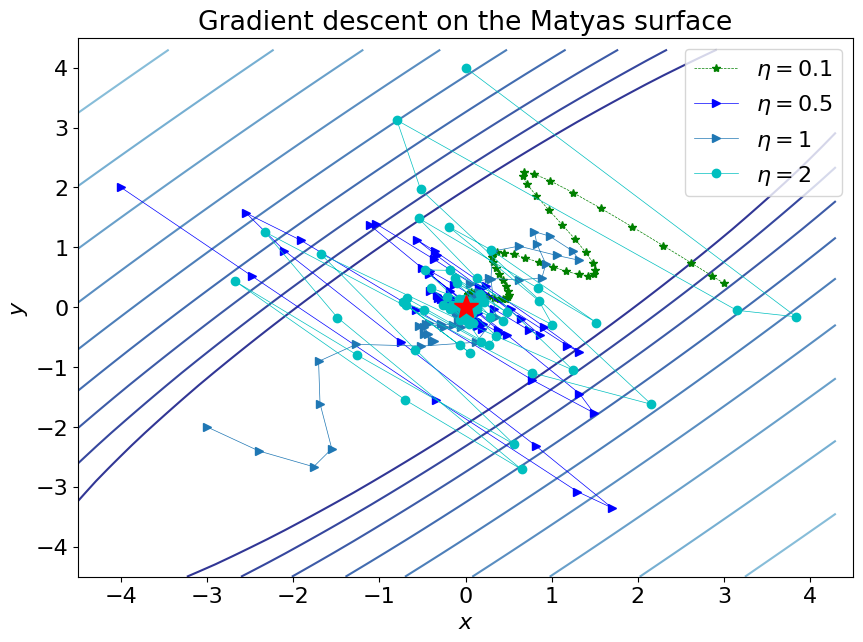

In [59]:
# Optional space for the momentum comparison.

# Investigate effect of learning rate in CM
plt.close()
fig = plt.figure(figsize=(10,7))
ax1 = fig.add_subplot(111)
x, y = np.meshgrid(np.arange(-4.5, 4.5, 0.2), np.arange(-4.5, 4.5, 0.2))
z=np.abs(matyas_surface(x,y))

#initial point
init4=[0,4]
init2=[-4,2]
init3=[-3,-2]
init1=[3,0.4]
eta1=0.1
eta2=0.5
eta3=1
eta4=2

ax1.contour(x, y, z, levels=np.logspace(0.0, 5, 35), norm=LogNorm(), cmap="RdYlBu_r")
ax1.set_title('Gradient descent on the Matyas surface')
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')

ax1.set_xlim((-4.5, 4.5))
ax1.set_ylim((-4.5, 4.5))

gd_1=gd_with_mom(grad_matyas_surface,init1, n_epochs=100, eta=eta1)
gd_2=gd_with_mom(grad_matyas_surface,init2, n_epochs=100, eta=eta2)
gd_3=gd_with_mom(grad_matyas_surface,init3, n_epochs=100, eta=eta3)
gd_4=gd_with_mom(grad_matyas_surface,init4, n_epochs=100, eta=eta4)

overlay_trajectory_contour(ax1,gd_1,r'$\eta=$%s'% eta1,'g--*', lw=0.5)
overlay_trajectory_contour(ax1,gd_2,r'$\eta=$%s'% eta2,'b->', lw=0.5)
overlay_trajectory_contour(ax1,gd_3,r'$\eta=$%s'% eta3,'->', lw=0.5)
overlay_trajectory_contour(ax1,gd_4,r'$\eta=$%s'% eta4,'c-o', lw=0.5)

ax1.plot(0,0, 'r*', markersize=18)

plt.legend()
plt.show()

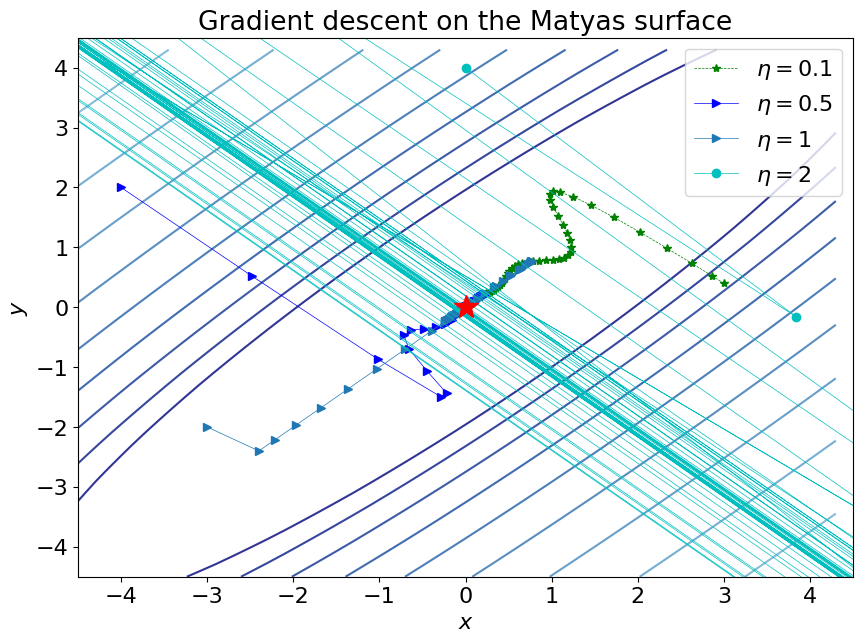

In [60]:
# Investigate effect of learning rate in NAG
plt.close()
fig = plt.figure(figsize=(10,7))
ax1 = fig.add_subplot(111)
x, y = np.meshgrid(np.arange(-4.5, 4.5, 0.2), np.arange(-4.5, 4.5, 0.2))
z=np.abs(matyas_surface(x,y))

#initial point
init4=[0,4]
init2=[-4,2]
init3=[-3,-2]
init1=[3,0.4]
eta1=0.1
eta2=0.5
eta3=1
eta4=2

ax1.contour(x, y, z, levels=np.logspace(0.0, 5, 35), norm=LogNorm(), cmap="RdYlBu_r")
ax1.set_title('Gradient descent on the Matyas surface')
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')

ax1.set_xlim((-4.5, 4.5))
ax1.set_ylim((-4.5, 4.5))

gd_1=NAG(grad_matyas_surface,init1, n_epochs=100, eta=eta1)
gd_2=NAG(grad_matyas_surface,init2, n_epochs=100, eta=eta2)
gd_3=NAG(grad_matyas_surface,init3, n_epochs=100, eta=eta3)
gd_4=NAG(grad_matyas_surface,init4, n_epochs=100, eta=eta4)

overlay_trajectory_contour(ax1,gd_1,r'$\eta=$%s'% eta1,'g--*', lw=0.5)
overlay_trajectory_contour(ax1,gd_2,r'$\eta=$%s'% eta2,'b->', lw=0.5)
overlay_trajectory_contour(ax1,gd_3,r'$\eta=$%s'% eta3,'->', lw=0.5)
overlay_trajectory_contour(ax1,gd_4,r'$\eta=$%s'% eta4,'c-o', lw=0.5)

ax1.plot(0,0, 'r*', markersize=18)

plt.legend()
plt.show()